In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
import pickle

data_dir = r'D:/data-distance-coding-project/processed-data'

# Loading the Data


In [2]:
imaging_filename = r'240731_SAM019_1'
imaging_dir = os.path.join(data_dir, imaging_filename)
object_filename = imaging_dir + '/' + imaging_filename + '_distance_spikes.pkl'

if os.path.exists(object_filename):
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')

Loaded DistanceAnalysis object


# 1. DL decoding

In [ ]:
# get the cells where is reliable one eye and two eye
reliable = np.where(np.array(D.stats['type']) != 'un-reliable')[0]
stimuli = np.linspace(0, 100, 100)

resp_all = []
for cell in reliable:
    cell_trace = D.get_all_traces(cell, mean_trace=True)[0]
    # normalize cell trace
    cell_trace = (cell_trace - np.min(cell_trace)) / (np.max(cell_trace) - np.min(cell_trace))
    resp_all.append(cell_trace)

resp_all = np.array(resp_all).T
n_stimuli, n_neurons = resp_all.shape
print('Number of neurons: ' + str(n_neurons))
print('Number of stimuli: ' + str(n_stimuli))

In [ ]:
plt.plot(resp_all[:, 6])

In [5]:
# Load data
import torch
from torch import nn
from torch import optim

In [7]:
class DeepNet(nn.Module):
  """Deep Network with one hidden layer

  Args:
    n_inputs (int): number of input units
    n_hidden (int): number of units in hidden layer

  Attributes:
    in_layer (nn.Linear): weights and biases of input layer
    out_layer (nn.Linear): weights and biases of output layer

  """

  def __init__(self, n_inputs, n_hidden):
    super().__init__()  # needed to invoke the properties of the parent class nn.Module
    self.in_layer = nn.Linear(n_inputs, n_hidden) # neural activity --> hidden units
    self.out_layer = nn.Linear(n_hidden, 1) # hidden units --> output

  def forward(self, r):
    """Decode stimulus orientation from neural responses

    Args:
      r (torch.Tensor): vector of neural responses to decode, must be of
        length n_inputs. Can also be a tensor of shape n_stimuli x n_inputs,
        containing n_stimuli vectors of neural responses

    Returns:
      torch.Tensor: network outputs for each input provided in r. If
        r is a vector, then y is a 1D tensor of length 1. If r is a 2D
        tensor then y is a 2D tensor of shape n_stimuli x 1.

    """
    h = self.in_layer(r)  # hidden representation
    y = self.out_layer(h)
    return y

In [8]:
class DeepNetReLU(nn.Module):
  """ network with a single hidden layer h with a RELU """

  def __init__(self, n_inputs, n_hidden):
    super().__init__()  # needed to invoke the properties of the parent class nn.Module
    self.in_layer = nn.Linear(n_inputs, n_hidden) # neural activity --> hidden units
    self.out_layer = nn.Linear(n_hidden, 1) # hidden units --> output

  def forward(self, r):

    h = self.in_layer(r)  # hidden representation
    h = torch.relu(h)  # rectified linear activation function
    y = self.out_layer(h)

    return y

In [9]:
def get_data(n_stim, train_data, train_labels):
  """ Return n_stim randomly drawn stimuli/resp pairs

  Args:
    n_stim (scalar): number of stimuli to draw
    resp (torch.Tensor):
    train_data (torch.Tensor): n_train x n_neurons tensor with neural
      responses to train on
    train_labels (torch.Tensor): n_train x 1 tensor with orientations of the
      stimuli corresponding to each row of train_data, in radians

  Returns:
    (torch.Tensor, torch.Tensor): n_stim x n_neurons tensor of neural responses and n_stim x 1 of orientations respectively
  """
  n_stimuli = train_labels.shape[0]
  istim = np.random.choice(n_stimuli, n_stim)
  r = train_data[istim]  # neural responses to this stimulus
  ori = train_labels[istim]  # true stimulus orientation

  return r, ori

In [ ]:
# Set random seeds for reproducibility
# Set random seeds for reproducibility
np.random.seed(4)
torch.manual_seed(4)

# Split data into training set and testing set
n_train = int(0.6 * n_stimuli)  # use 60% of all data for training set
ishuffle = torch.randperm(n_stimuli)
itrain = ishuffle[:n_train]  # indices of data samples to include in training set
itest = ishuffle[n_train:]  # indices of data samples to include in testing set
stimuli_test = stimuli[itest]
resp_test = resp_all[itest]
stimuli_train = stimuli[itrain]
resp_train = resp_all[itrain]

np.random.seed(1)
torch.manual_seed(1)

# Initialize a deep network with M=200 hidden units
net = DeepNetReLU(n_neurons, 200)

# Get neural responses (r) to and orientation (ori) to one stimulus in dataset
r, ori = get_data(1, resp_train, stimuli_train)  # using helper function get_data

# Decode orientation from these neural responses using initialized network
out = net(torch.Tensor(r))  # compute output from network, equivalent to net.forward(r)

print(f'decoded orientation: {out.item():.2f} degrees')
print(f'true orientation: {ori.item():.2f} degrees')

In [ ]:
np.random.seed(1)
torch.manual_seed(1)

# Initialize a deep network with M=10 hidden units
net = DeepNetReLU(n_neurons, 1)

# Get neural responses to first 20 stimuli in the data set
r, ori = get_data(20, resp_train, stimuli_train)

print(r.shape)
print(ori.shape)

# Decode orientation from these neural responses
out = np.squeeze(net(torch.Tensor(r)))
ori = torch.Tensor(ori)

# # Initialize PyTorch mean squared error loss function (Hint: look at nn.MSELoss)
loss_fn = nn.MSELoss()

# # Evaluate mean squared error
loss = loss_fn(out, ori)

print(f'mean squared error: {loss:.2f}')

In [33]:
def train(net, loss_fn, train_data, train_labels,
          n_epochs=50, learning_rate=1e-4):
    """Run gradient descent to optimize parameters of a given network

    Args:
      net (nn.Module): PyTorch network whose parameters to optimize
      loss_fn: built-in PyTorch loss function to minimize
      train_data (torch.Tensor): n_train x n_neurons tensor with neural
        responses to train on
      train_labels (torch.Tensor): n_train x 1 tensor with orientations of the
        stimuli corresponding to each row of train_data
      n_epochs (int, optional): number of epochs of gradient descent to run
      learning_rate (float, optional): learning rate to use for gradient descent

    Returns:
      (list): training loss over iterations

    """

    # Initialize PyTorch SGD optimizer
    optimizer = optim.SGD(net.parameters(), lr=learning_rate)

    # Placeholder to save the loss at each iteration
    train_loss = []

    # Loop over epochs
    for i in range(n_epochs):
        # compute network output from inputs in train_data
        out = net(train_data)  # Forward pass

        # evaluate loss function
        loss = loss_fn(out, train_labels)

        # Clear previous gradients
        optimizer.zero_grad()

        # Compute gradients
        loss.backward()

        # Update weights
        optimizer.step()

        # Store current value of loss
        train_loss.append(loss.item())  # .item() needed to transform the tensor output of loss_fn to a scalar

        # Track progress
        if (i + 1) % (n_epochs // 5) == 0:
            print(f'iteration {i + 1}/{n_epochs} | loss: {loss.item():.3f}')

    return train_loss

In [16]:
def plot_train_loss(train_loss):
  plt.plot(train_loss)
  plt.xlim([0, None])
  plt.ylim([0, None])
  plt.xlabel('iterations of gradient descent')
  plt.ylabel('mean squared error')
  plt.show()

In [ ]:
# Set random seeds for reproducibility
np.random.seed(1)
torch.manual_seed(1)

# Initialize network with 10 hidden units
net = DeepNetReLU(n_neurons, 1)

# Initialize built-in PyTorch MSE loss function
loss_fn = nn.MSELoss()

# Run gradient descent on data
train_loss = train(net, loss_fn, np.squeeze(torch.Tensor(resp_train)), torch.Tensor(stimuli_train), n_epochs=100)

# Plot the training loss over iterations of GD
plot_train_loss(train_loss)

In [45]:
# evalue the network on all the data
out = np.squeeze(net(torch.Tensor(resp_test)))
ori = torch.Tensor(stimuli_test)
loss = loss_fn(out, ori)
print(f'mean squared error: {loss:.2f}')

mean squared error: 1727.00


# 2. Linear decoder


In [91]:
import numpy as np

class LinearDecoder:
    def __init__(self, num_neurons=350):
        """
        Initialize a linear decoder for visual stimulus location prediction

        Parameters:
        -----------
        num_neurons : int, optional (default=350)
            Number of input neurons representing neural activity
        """
        self.num_neurons = num_neurons
        self.weights = None

    def fit(self, X, y):
        """
        Train the linear decoder using least squares regression

        Parameters:
        -----------
        X : numpy.ndarray
            Input neural activity matrix of shape (n_samples, num_neurons)
        y : numpy.ndarray
            Target locations of shape (n_samples, location_dimensions)
        """
        # Compute the pseudoinverse (least squares solution)
        self.weights = np.linalg.pinv(X.T @ X) @ X.T @ y

        return self

    def predict(self, X):
        """
        Predict stimulus location based on neural activity

        Parameters:
        -----------
        X : numpy.ndarray
            Input neural activity matrix of shape (n_samples, num_neurons)

        Returns:
        --------
        numpy.ndarray
            Predicted locations
        """
        if self.weights is None:
            raise ValueError("Decoder must be trained first. Call fit() method.")

        return X @ self.weights

    def evaluate(self, X, y_true):
        """
        Evaluate decoder performance using Mean Squared Error

        Parameters:
        -----------
        X : numpy.ndarray
            Input neural activity matrix
        y_true : numpy.ndarray
            True stimulus locations

        Returns:
        --------
        dict
            Performance metrics including MSE and R-squared
        """
        y_pred = self.predict(X)

        # Mean Squared Error
        mse = np.mean((y_true - y_pred)**2)

        # R-squared (coefficient of determination)
        ss_total = np.sum((y_true - np.mean(y_true, axis=0))**2)
        ss_residual = np.sum((y_true - y_pred)**2)
        r_squared = 1 - (ss_residual / ss_total)

        return {
            'mean_squared_error': mse,
            'r_squared': r_squared
        }

# downsample repeat trace
def downsample_repeat_trace(cell, repeat, n_samples):

    leg_trace = D.get_repeat_trace(cell, repeat)
    leg_angles = D.get_repeat_angles(repeat)

    angle_range = np.linspace(-40, 60, n_samples)
    # apply gaussian window to leg_trace
    # leg_trace = np.convolve(leg_trace, np.ones(3) / 3, mode='same')

    return np.interp(angle_range, leg_angles, leg_trace), np.linspace(-40, 60, n_samples)

def downsample_all_traces(cell, n_samples, distance=None, block=None, mean_trace=True):

    all_traces = []

    if block is None:
        trace_vector = range(len(D.distance_mat))
    elif block == 'one eye':
        trace_vector = D.one_eye.flatten()
    elif block == 'two eye':
        trace_vector = D.two_eye.flatten()
    else:
        print('Block not recognized')
        return

    for repeat in trace_vector:

        if distance is not None:
            for dist in distance:
                if D.distance_mat[repeat] != dist:
                    continue

                rep_trace, angle_range = downsample_repeat_trace(cell, repeat, n_samples)
                all_traces.append(rep_trace)

        else:

            rep_trace, angle_range = downsample_repeat_trace(cell, repeat, n_samples)
            all_traces.append(rep_trace)

    # scale all trace to values between 0 and 1
    all_traces = (all_traces - np.min(all_traces)) / (np.max(all_traces) - np.min(all_traces))

    if mean_trace:
        return np.median(all_traces, axis=0), angle_range
    else:
        return np.array(all_traces), angle_range

def get_all_data(n_samples, repeat=None, block=None):

    X = []
    for cell in range(len(D.dFF)):

        if repeat is not None:
            cell_trace, y = downsample_repeat_trace(cell, repeat, n_samples)

        else:
            cell_trace, y = downsample_all_traces(cell, n_samples, distance=[1,2,3,4, 5], block=block, mean_trace=True)


        # apply gaussian window to cell_trace
        # cell_trace = np.convolve(cell_trace, np.ones(5) / 5, mode='same')
        # normalize cell trace
        # cell_trace = (cell_trace - np.min(cell_trace)) / (np.max(cell_trace) - np.min(cell_trace))
        X.append(cell_trace)

    return np.array(X).T, y

def split_train_and_test(X, y, train_ratio=0.8):

    n_stimuli = X.shape[0]
    n_train = int(train_ratio * n_stimuli)
    split_idx = np.arange(n_stimuli)

    np.random.shuffle(split_idx)

    # shuffle
    X_train, X_test = X[split_idx[:n_train]], X[split_idx[n_train:]]
    y_train, y_test = y[split_idx[:n_train]], y[split_idx[n_train:]]

    return X_train, X_test, y_train, y_test

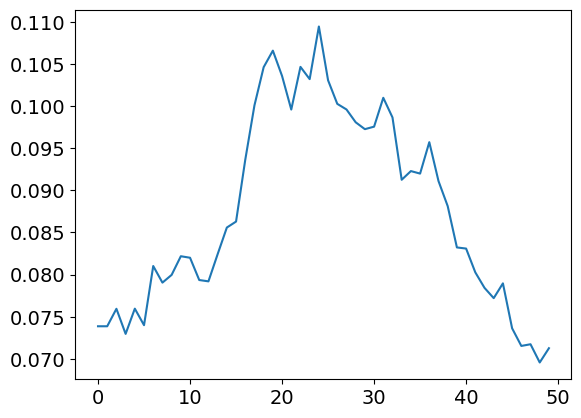

In [81]:
cell_trace = downsample_all_traces(cell=16, n_samples=50, distance=[1,2,3,4], mean_trace=True)[0]
plt.plot(cell_trace)

In [97]:
n_samples = 60
X, y = get_all_data(n_samples = n_samples, block='two eye')
y = np.linspace(0, 1, n_samples)
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.7)
decoder = LinearDecoder()
decoder.fit(X, y)
performance = decoder.evaluate(X_test, y_test)

for metric, value in performance.items():
    print(f"{metric}: {value}")

mse = []
weights = []
# evaluate in individual repeats

mean_squared_error: 3.989913498722152e-06
r_squared: 0.9999517043015363


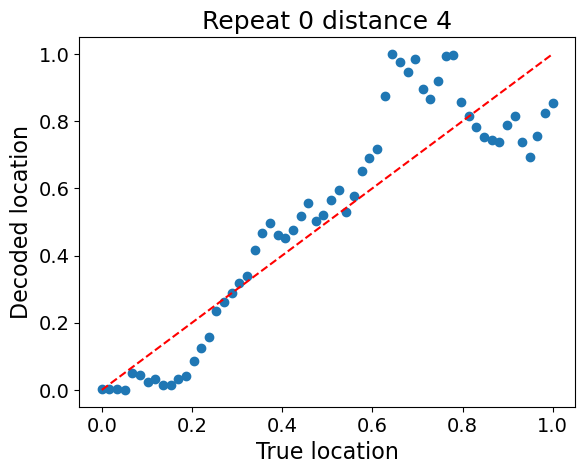

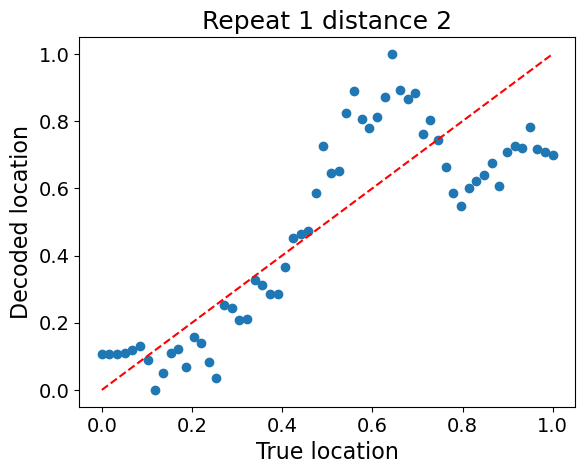

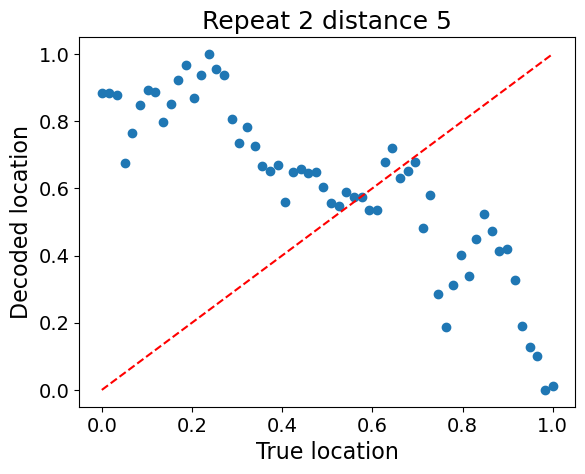

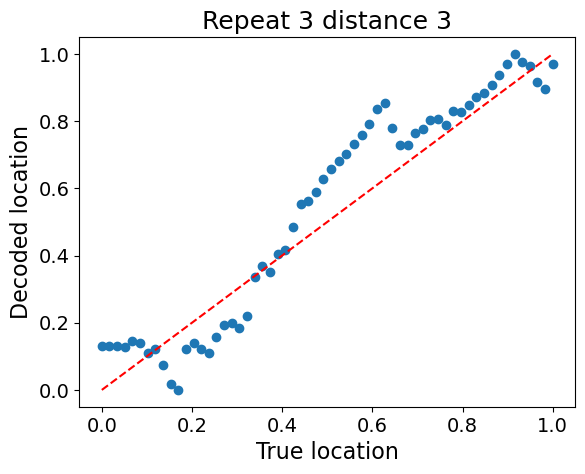

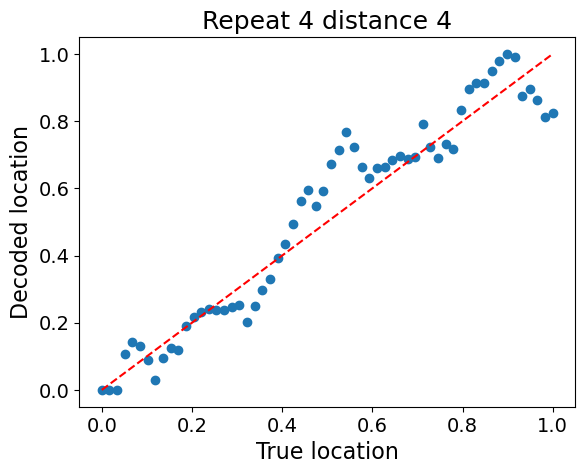

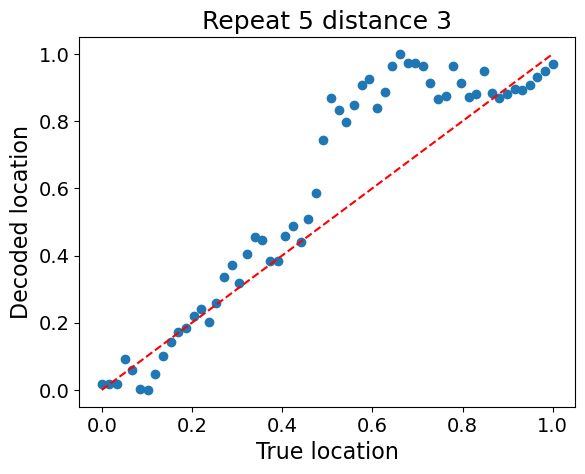

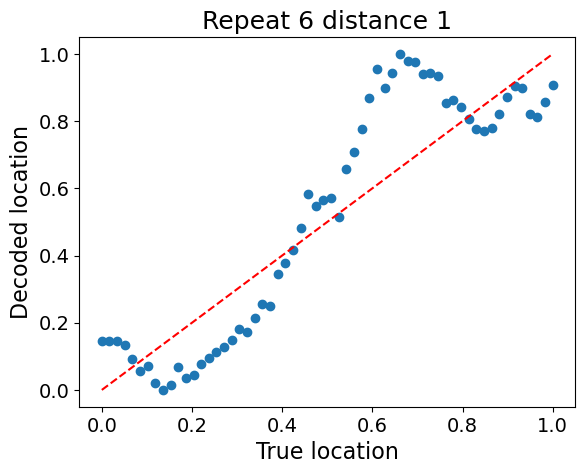

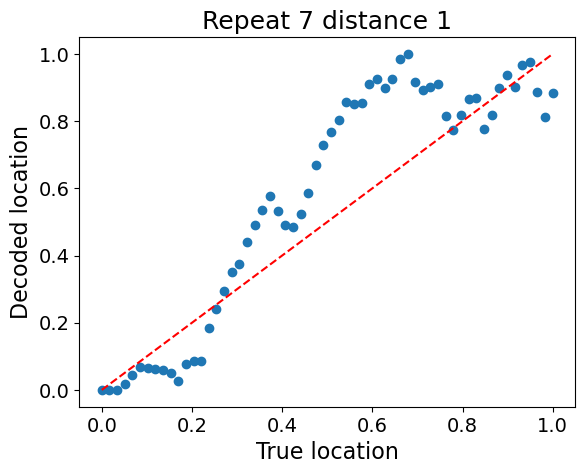

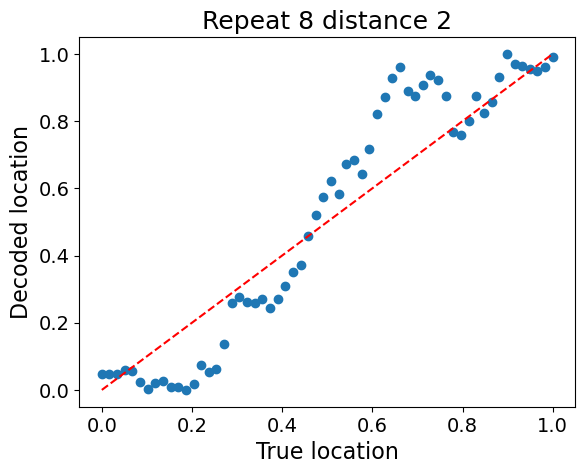

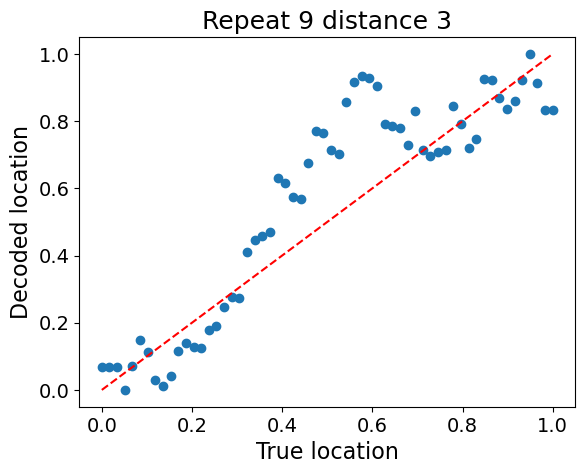

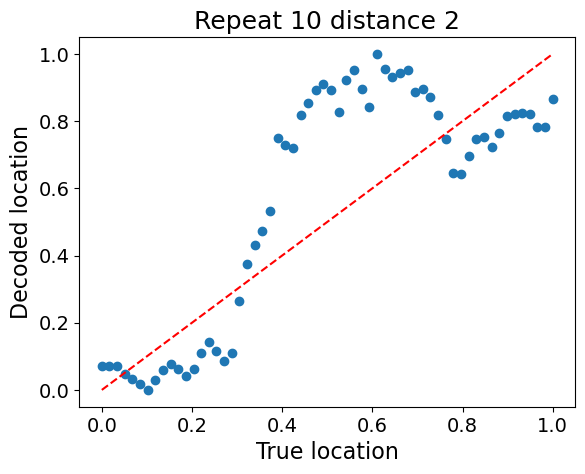

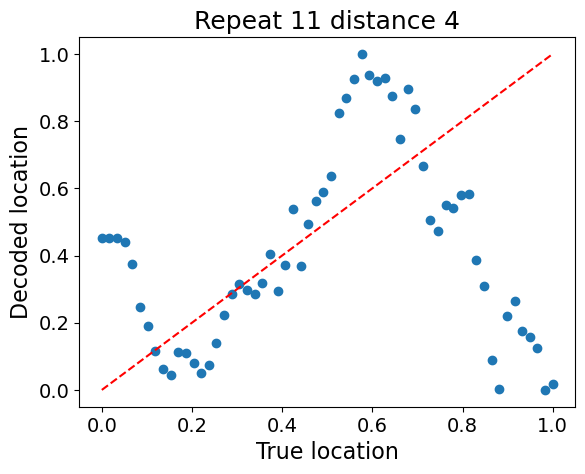

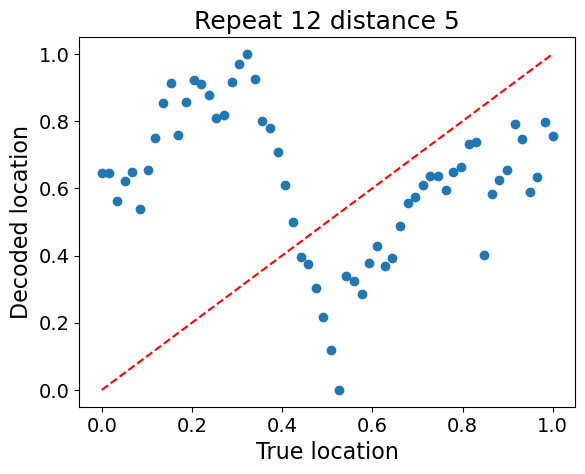

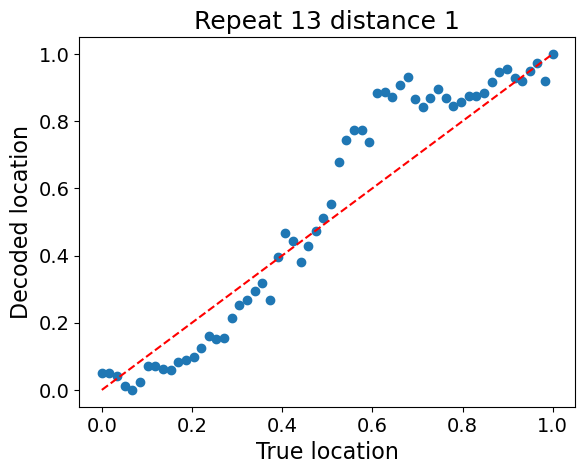

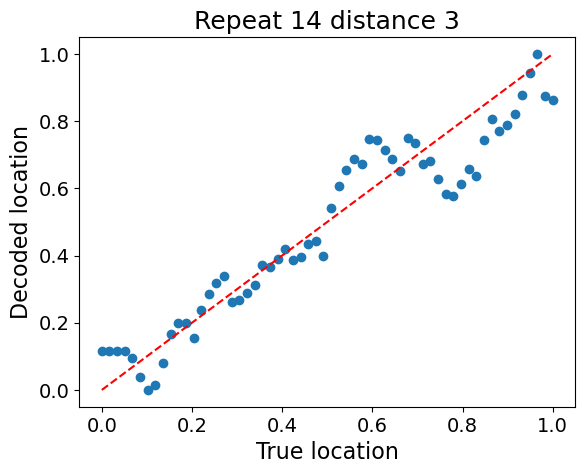

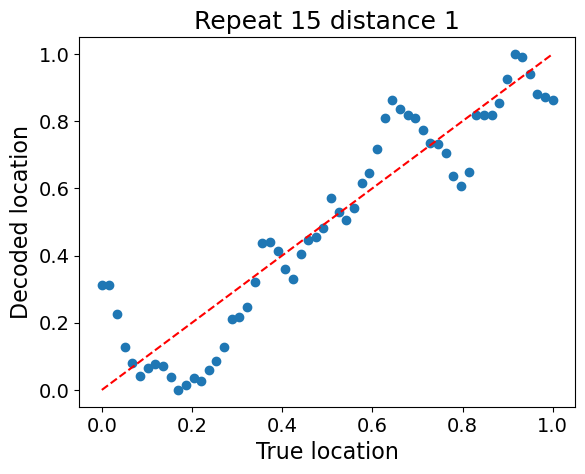

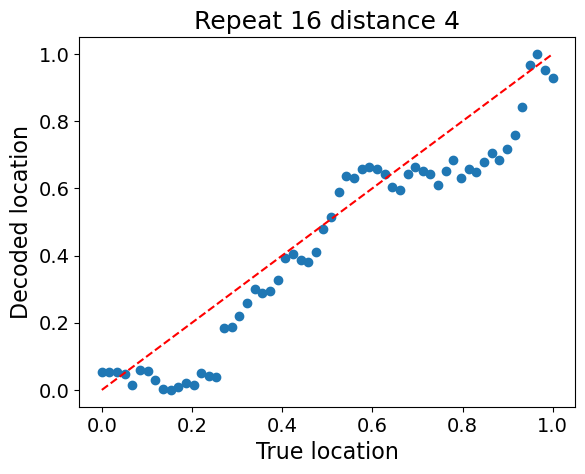

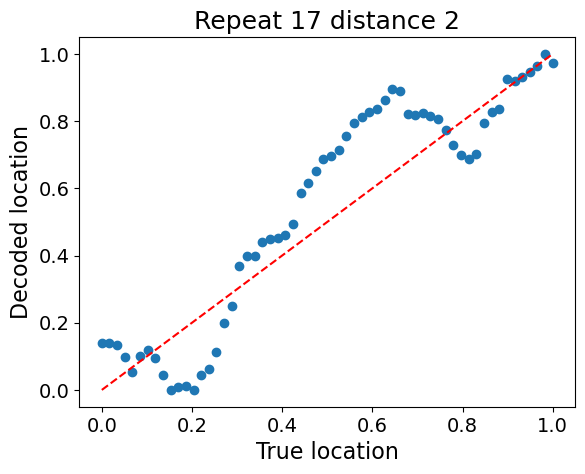

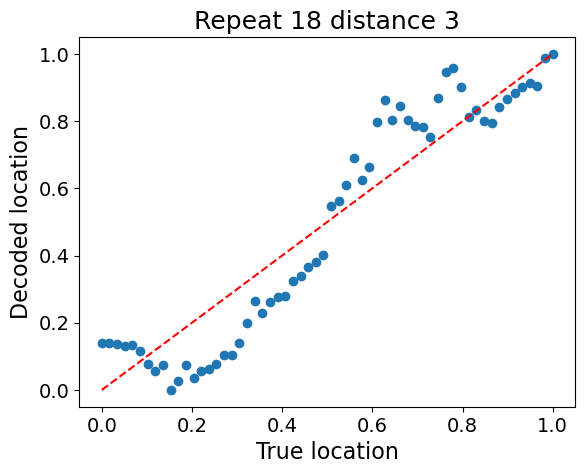

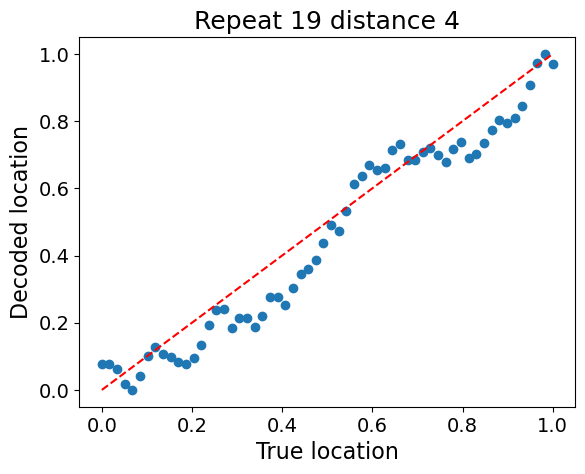

In [98]:
for repeat in range(20):

    X, y = get_all_data(n_samples = 60, repeat=repeat)
    y = np.linspace(0, 1, n_samples)
    y_pred = decoder.predict(X)

    #scale y_pred to values between 0 and 1
    y_pred = (y_pred - np.min(y_pred)) / (np.max(y_pred) - np.min(y_pred))

    plt.figure()
    plt.title('Repeat ' + str(repeat) + ' distance ' + str(D.distance_mat[repeat]))
    plt.plot(np.linspace(0, 1, n_samples), y_pred, 'o')
    plt.xlabel('True location')
    plt.ylabel('Decoded location')
    plt.plot([0, 1], [0, 1], 'r--')

    mse.append(np.mean((y - y_pred)**2))

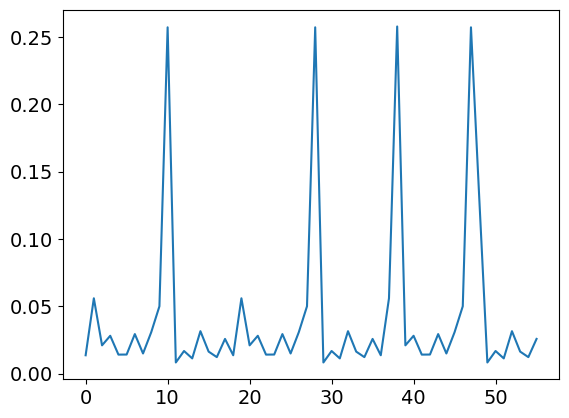

In [90]:
plt.plot(mse)

(160, 617)


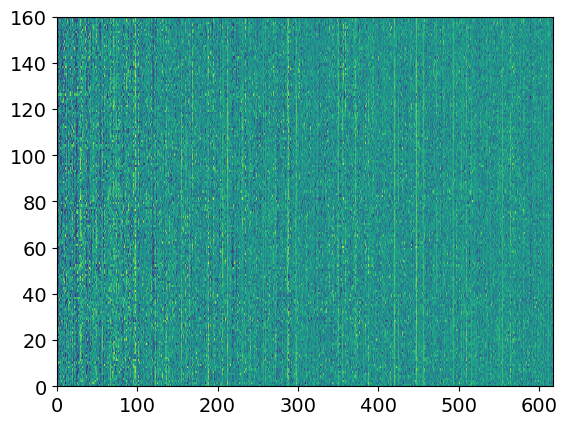

In [16]:
print(np.shape(weights))

plt.pcolor(weights)

In [ ]:
# set random seed
np.random.seed(1)

sample_vec = np.arange(20, 100, 5)
mse = []
r_squared = []

for n_samples in sample_vec:
    print('Number of samples: ' + str(n_samples))

    X, y = get_all_data(n_samples = n_samples)
    X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.7)
    # Create and train decoder
    decoder = LinearDecoder()
    decoder.fit(X_train, y_train)
    # Evaluate performance
    performance = decoder.evaluate(X_test, y_test)

    mse.append(performance['mean_squared_error'])
    r_squared.append(performance['r_squared'])

    print("Decoder Performance:")
    for metric, value in performance.items():
        print(f"{metric}: {value}")

    print()

In [905]:
n_samples = 60
# set random seed
np.random.seed(1)
D.activity_mode = 'dFF'
X, y = get_all_data(n_samples = n_samples, block='two eye')
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.8)
# Create and train decoder
decoder = LinearDecoder()
decoder.fit(X_train, y_train)
performance = decoder.evaluate(X_test, y_test)
for metric, value in performance.items():
    print(f"{metric}: {value}")

X, y = get_all_data(n_samples = n_samples, block='one eye')
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.8)
# Create and train decoder
decoder = LinearDecoder()
decoder.fit(X_train, y_train)
performance = decoder.evaluate(X_test, y_test)
for metric, value in performance.items():
    print(f"{metric}: {value}")

X, y = get_all_data(n_samples = n_samples)
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.8)
# Create and train decoder
decoder = LinearDecoder()
decoder.fit(X_train, y_train)
performance = decoder.evaluate(X_test, y_test)
for metric, value in performance.items():
    print(f"{metric}: {value}")

mean_squared_error: 4.659594979925242
r_squared: 0.994544316504678
mean_squared_error: 0.646689603955681
r_squared: 0.9991470088739383
mean_squared_error: 0.85870967900427
r_squared: 0.998940637309174


Text(0.5, 1.0, 'Repeat 10 distance 2 MSE: 519.0')

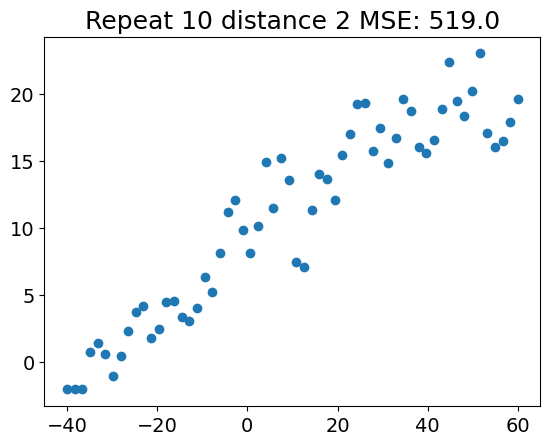

In [907]:
repeat = 1
X, y = get_all_data(n_samples = n_samples, repeat = repeat)
y_pred = decoder.predict(X)

mse = np.mean((y - y_pred)**2)

plt.plot(y, y_pred, 'o')
plt.title('Repeat ' + str(repeat) +  ' distance ' + str(D.distance_mat[repeat]) + ' MSE: ' + str(round(mse,1)))

Text(0, 0.5, 'R-squared')

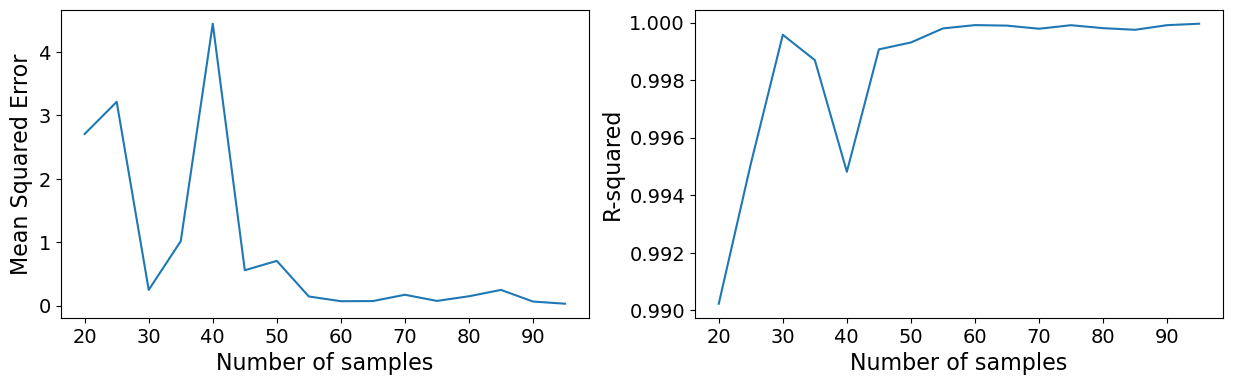

In [509]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(sample_vec, mse)
ax[0].set_xlabel('Number of samples')
ax[0].set_ylabel('Mean Squared Error')

ax[1].plot(sample_vec, r_squared)
ax[1].set_xlabel('Number of samples')
ax[1].set_ylabel('R-squared')

In [510]:
X, y = get_all_data(n_samples = 60)
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.7)
# Create and train decoder
decoder = LinearDecoder()
decoder.fit(X_train, y_train)
# Evaluate performance
performance = decoder.evaluate(X_test, y_test)

In [500]:
print(performance)

{'mean_squared_error': 0.7822752336696401, 'r_squared': 0.9991635653023259}


In [917]:
n_samples = 50
X, y = get_all_data(n_samples = n_samples)
X_train, X_test, y_train, y_test = split_train_and_test(X, y, train_ratio=0.8)
# Create and train decoder
decoder = LinearDecoder()
decoder.fit(X_train, y_train)
# Evaluate performance
performance = decoder.evaluate(X_test, y_test)

mse = []
r_squared = []
for repeat in range(len(D.distance_mat)):

    if D.distance_mat[repeat] == 5:
        continue

    X, y = get_all_data(n_samples = n_samples, repeat=repeat)
    y_pred = decoder.predict(X)

    mse.append(np.mean((y - y_pred)**2))
    ss_total = np.sum((y - np.mean(y, axis=0))**2)
    ss_residual = np.sum((y - y_pred)**2)
    r_squared.append(1 - (ss_residual / ss_total))

Text(0, 0.5, 'R-squared')

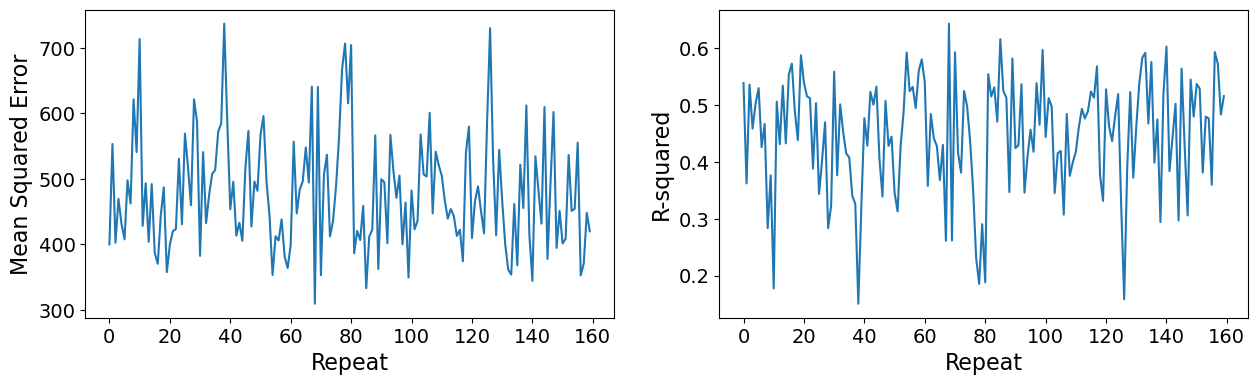

In [918]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(mse)
ax[0].set_xlabel('Repeat')
ax[0].set_ylabel('Mean Squared Error')

ax[1].plot(r_squared)
ax[1].set_xlabel('Repeat')
ax[1].set_ylabel('R-squared')


In [ ]:
# predict stimulus location
y_pred = decoder.predict(X_test)
print(X_test.shape)
plt.plot(y_test, y_pred, 'o')
plt.xlabel('True location')
plt.ylabel('Decoded location')
# plot a line
plt.plot([-40, 60], [-40, 60], 'r--')

# plot decoding error as function of location
decoder_error = []
for i, (sample_X, sample_y) in enumerate(zip(X_test, y_test)):
    result = decoder.predict(sample_X)
    decoder_error.append(result - sample_y)

plt.figure()
plt.plot(y_test, decoder_error, 'o')

# print which index are the ten bigger and the ten smaller weights
print(np.argsort(decoder.weights)[:10])
print(np.argsort(decoder.weights)[-10:])
print(decoder.weights.shape)

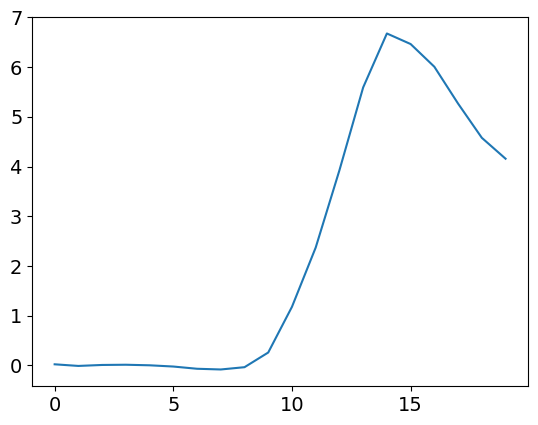

In [477]:
# repeat_trace, repeat_angles = downsample_repeat_trace(cell=155, repeat=4, n_samples=50)
# plt.plot(repeat_angles, repeat_trace, 'o')

all_traces = downsample_all_traces(cell=155, n_samples=20, distance=[1,2,3,4], mean_trace=True)

plt.plot(all_traces)

(100, 617)
(617,)


Text(0.5, 1.0, 'Trial #3')

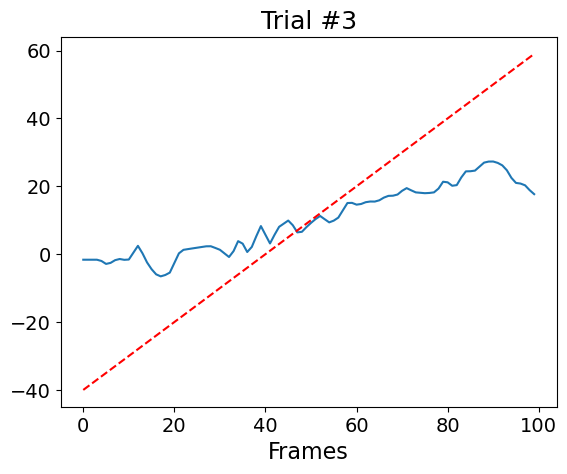

In [922]:
trial = 3
resp_norm = []
for cell in range(len(D.dFF)):
    cell_trace, _ = D.interpolate_repeat_trace(cell, repeat=trial)
    # smooth with a gaussian filter
    # cell_trace = np.convolve(cell_trace, np.ones(5) / 5, mode='same')
    # normalize cell trace
    cell_trace = (cell_trace - np.min(cell_trace)) / (np.max(cell_trace) - np.min(cell_trace))
    # if cell_trace is nan, set it to 0
    cell_trace[np.isnan(cell_trace)] = 0
    resp_norm.append(cell_trace)

resp_norm = np.array(np.squeeze(resp_norm)).T

print(resp_norm.shape)
print(decoder.weights.shape)

y_pred = []
for i in range(resp_norm.shape[0]):
    x = resp_norm[i, :]
    y_pred.append(decoder.predict(x))

plt.plot(y_pred, label='Decoded location')
plt.plot(np.arange(100), np.arange(-40, 60, 1), 'r--', label='True location')
plt.xlabel('Frames')
plt.title('Trial #'  + str(trial))
# plt.plot(np.squeeze(D.interpolate_repeat_trace(0, repeat=4))[1])
#
# print(D.interpolate_repeat_trace(0, repeat=4)[1][0])

# 3. Bayesian decoder

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

class SingleDimensionBayesianDecoder:
    def __init__(self, num_neurons=350):
        """
        Bayesian decoder for single dimension stimulus location

        Parameters:
        -----------
        num_neurons : int
            Number of input neurons
        """
        self.num_neurons = num_neurons
        self.location_bins = None
        self.neural_means = None
        self.neural_stds = None

    def fit(self, X, y, num_bins=20):
        """
        Estimate probability distributions

        Parameters:
        -----------
        X : numpy.ndarray
            Neural activity (samples x neurons)
        y : numpy.ndarray
            Stimulus locations (1D)
        num_bins : int
            Number of location bins to discretize space
        """
        # Create location bins
        self.location_bins = np.linspace(y.min(), y.max(), num_bins)

        # Initialize storage for neural activity statistics
        self.neural_means = np.zeros((num_bins, self.num_neurons))
        self.neural_stds = np.zeros((num_bins, self.num_neurons))

        # Compute neural activity statistics for each location bin
        for i, bin_edge in enumerate(self.location_bins):
            if i < len(self.location_bins) - 1:
                # Mask for locations in this bin
                bin_mask = (y >= bin_edge) & (y < self.location_bins[i+1])

                if np.sum(bin_mask) > 0:
                    # Compute mean and standard deviation of neural activity
                    bin_X = X[bin_mask]
                    self.neural_means[i] = np.mean(bin_X, axis=0)
                    self.neural_stds[i] = np.std(bin_X, axis=0)

    def predict(self, X, prior=None):
        """
        Bayesian decoding of stimulus location

        Parameters:
        -----------
        X : numpy.ndarray
            Input neural activity
        prior : numpy.ndarray, optional
            Prior probability distribution of locations

        Returns:
        --------
        dict
            Posterior probabilities and most likely location
        """
        # If no prior, assume uniform
        if prior is None:
            prior = np.ones(len(self.location_bins)) / len(self.location_bins)

        # Compute likelihood for each location bin
        log_likelihoods = []

        for i in range(len(self.location_bins)):
            # Skip bins with no data
            if np.all(self.neural_stds[i] == 0):
                log_likelihoods.append(-np.inf)
                continue

            # Compute log-likelihood using independent neuron assumptions
            # Gaussian likelihood for each neuron
            neuron_likelihoods = stats.norm.logpdf(
                X,
                loc=self.neural_means[i],
                scale=self.neural_stds[i] + 1e-10  # Avoid division by zero
            )

            # Sum log-likelihoods across neurons
            log_likelihood = np.sum(neuron_likelihoods)

            # Bayesian update (log space to avoid numerical issues)
            log_posterior = log_likelihood + np.log(prior[i])
            log_likelihoods.append(log_posterior)

        # Convert log-likelihoods to probabilities
        likelihoods = np.exp(log_likelihoods - np.max(log_likelihoods))
        posteriors = likelihoods / np.sum(likelihoods)

        # Most likely location (bin center)
        most_likely_idx = np.argmax(posteriors)
        most_likely_location = self.location_bins[most_likely_idx]

        return {
            'locations': self.location_bins,
            'posteriors': posteriors,
            'most_likely_location': most_likely_location
        }

# Data generation with controlled single-dimension relationship
def generate_example_data(num_samples=1000, num_neurons=350):
    """
    Generate synthetic data with location-specific neural activity

    Returns:
    --------
    X : numpy.ndarray
        Neural activity
    y : numpy.ndarray
        Stimulus locations (1D)
    """
    # Create ground truth locations
    y = np.linspace(0, 10, num_samples)

    # Simulate neural activity with location-dependent noise
    X = np.zeros((num_samples, num_neurons))

    for i in range(num_neurons):
        # Create neuron-specific tuning to location
        neuron_slope = np.random.normal(1, 0.2)
        neuron_noise = np.random.normal(0, 0.5, num_samples)

        # Neural activity depends on location with some noise
        X[:, i] = neuron_slope * y + neuron_noise

    return X, y

# Visualization and evaluation
def plot_decoding_results(decoder, X_test, y_test):
    """
    Visualize Bayesian decoding results
    """
    plt.figure(figsize=(12, 6))

    # Store predictions
    predictions = []
    true_locations = []

    # Decode each test sample
    for i, (sample_X, sample_y) in enumerate(zip(X_test, y_test)):
        result = decoder.predict(sample_X)
        predictions.append(result['most_likely_location'])
        true_locations.append(sample_y)

    # Plotting
    plt.subplot(121)
    plt.scatter(true_locations, predictions, alpha=0.5)
    plt.plot([-40, 60], [-40, 60], 'r--')  # Ideal prediction line
    plt.title('True vs Predicted Locations')
    plt.xlabel('True Location')
    plt.ylabel('Predicted Location')

    plt.subplot(122)
    plt.scatter(true_locations,
                np.array(predictions) - np.array(true_locations),
                alpha=0.5)
    plt.title('Decoding Error')
    plt.xlabel('True Location')
    plt.ylabel('Prediction Error')
    plt.axhline(y=0, color='r', linestyle='--')

    plt.tight_layout()
    plt.show()

    # Compute error metrics
    mse = np.mean((np.array(true_locations) - np.array(predictions))**2)
    mae = np.mean(np.abs(np.array(true_locations) - np.array(predictions)))

    print(f"Mean Squared Error: {mse:.4f}")
    print(f"Mean Absolute Error: {mae:.4f}")

# Main execution
if __name__ == "__main__":
    # Set random seed for reproducibility
    # np.random.seed(42)

    reliable = np.where(np.array(D.stats['type']) != 'un-reliable')[0]

    # # one eye responsive cells
    # reliable = np.where(np.array(D.stats['preferred_angle'])<30)[0]

    resp_all = []
    for cell in range(len(D.dFF)):

        cell_trace = D.get_all_traces(cell, mean_trace=True)[0]
        # normalize cell trace
        cell_trace = (cell_trace - np.min(cell_trace)) / (np.max(cell_trace) - np.min(cell_trace))
        resp_all.append(cell_trace)


    resp_all = np.array(resp_all).T
    n_stimuli, n_neurons = resp_all.shape

    X = resp_all

    # create a vector that goes from -40 to 60 in increments of 1
    y = np.arange(-40, 60, 1)

    # Split into train and test sets
    train_ratio = 0.6

    # shuffle what x_train and x_test we are going to get
    n_train = int(train_ratio * n_stimuli)
    split_idx = np.arange(X.shape[0])

    # take 80% of the data for training and have a random seed
    # np.random.seed(1)
    np.random.shuffle(split_idx)

    # shuffle
    X_train, X_test = X[split_idx[:n_train]], X[split_idx[n_train:]]
    y_train, y_test = y[split_idx[:n_train]], y[split_idx[n_train:]]

    # Train Bayesian decoder
    decoder = SingleDimensionBayesianDecoder(num_neurons=n_neurons)
    decoder.fit(X_train, y_train)

    # Visualize and evaluate results
    plot_decoding_results(decoder, X_test, y_test)

    # plot decoder error as function of location
    decoder_error = []
    for i, (sample_X, sample_y) in enumerate(zip(X_test, y_test)):
        result = decoder.predict(sample_X)
        decoder_error.append(result['most_likely_location'] - sample_y)

In [ ]:
resp = D.spks[reliable, :]
frames = D.get_repeat_frames(repeat=10)[0]
resp = resp[:, frames].T

print(resp.shape)

resp_norm = []
for cell in range(resp.shape[1]):
    cell_trace = resp[:, cell]
    # smooth with a gaussian filter
    cell_trace = np.convolve(cell_trace, np.ones(5) / 5, mode='same')
    # normalize cell trace
    cell_trace = (cell_trace - np.min(cell_trace)) / (np.max(cell_trace) - np.min(cell_trace))
    # if cell_trace is nan, set it to 0
    cell_trace[np.isnan(cell_trace)] = 0
    resp_norm.append(cell_trace)

resp_norm = np.array(resp_norm).T
print(resp_norm.shape)

y = []
for i in range(resp_norm.shape[0]):
    x = resp_norm[i, :]
    y.append(decoder.predict(x))

plt.plot(y)
# print(X.shape)

# # normalize by columns
# X = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
#
# # for every time point in X, get the prediction
# y = []
# for i in range(X.shape[0]):
#     x = X[i,:]
#     # normalize
#     y.append(decoder.predict(x))
#
# plt.plot(y)